# Chapitre 8 - Cours 1 : Curation des données

Un modèle ne vaut que ce que valent ses données d'entraînement : même avec un calcul
illimité, une équipe ne peut pas affiner un bon modèle sans bonnes données. Le chapitre 8
du livre traite de l'**ingénierie des données** (« dataset engineering ») : construire le
jeu de données qui permet d'entraîner le meilleur modèle possible dans un budget donné.

Ce premier notebook couvre l'introduction du chapitre et la section *Data Curation* :

1. la vision **centrée sur les données** (encadré *A Data-Centric View of AI*) ;
2. **quelles données** pour quelle phase d'entraînement (formats, chaîne de pensée, outils) ;
3. la **qualité** des données (section *Data Quality*), avec une expérience sur le bruit
   d'étiquetage ;
4. la **couverture** et la diversité (section *Data Coverage*), mesurées et expérimentées ;
5. la **quantité** (section *Data Quantity*) : courbes d'apprentissage, loi de puissance,
   budget ;
6. l'**acquisition et l'annotation** (section *Data Acquisition and Annotation*) :
   entonnoir de constitution, consignes, accord inter-annotateurs (kappas de Cohen et de
   Fleiss implémentés).

Pour isoler les effets étudiés, on utilise un « petit monde » contrôlé : un problème de
classification synthétique où l'on connaît la vérité terrain, et un classifieur rapide
(SVM). Les conclusions qualitatives se transposent à l'affinage des LLM, que l'on ne
peut pas réentraîner des dizaines de fois dans un notebook.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.svm import SVC

from aie import ch08_donnees as d8
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                          annotate_bars, finish, set_style, subtitle)

warnings.filterwarnings("ignore")
set_style()
plt.rcParams["mathtext.fontset"] = "dejavusans"  # glyphes complets pour les exposants des axes log
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)


def titre(ax, texte, sous_titre):
    """Titre d'axe suivi d'un sous-titre gris (le titre est décalé pour lui laisser la place)."""
    ax.set_title(texte, pad=18)
    subtitle(ax, sous_titre)

## 1. Une vision centrée sur les données (section *A Data-Centric View of AI*)

**Le problème.** Pendant des années, la recherche en apprentissage profond a été
**centrée sur le modèle** : on fixe un jeu de données (ImageNet...) et l'on cherche la
meilleure architecture, la meilleure technique d'entraînement. Or, aujourd'hui, peu
d'entreprises entraînent des modèles de fondation à partir de zéro : elles partent toutes
des mêmes modèles ouverts ou des mêmes API. **Ce qui les différencie, ce sont leurs
données.**

L'approche **centrée sur les données** inverse la question : *à modèle fixé, quel jeu de
données donne les meilleures performances ?* Le livre cite des compétitions construites
sur ce principe (le concours d'Andrew Ng en 2021, DataComp en 2023 où un script
d'entraînement standard évalue chaque jeu de données soumis sur 38 tâches). Il note
aussi que le nombre de personnes créditées pour le travail sur les données est passé
d'une poignée pour GPT-3 à environ quatre-vingts pour GPT-4.

**Intuition culinaire** (reprise par le livre) : entraîner un modèle, c'est cuisiner.
La **qualité** des données est la fraîcheur des ingrédients, la **couverture** est
l'équilibre de la recette, la **quantité** est le volume d'ingrédients. Ce sont les trois
critères qui structurent la curation.

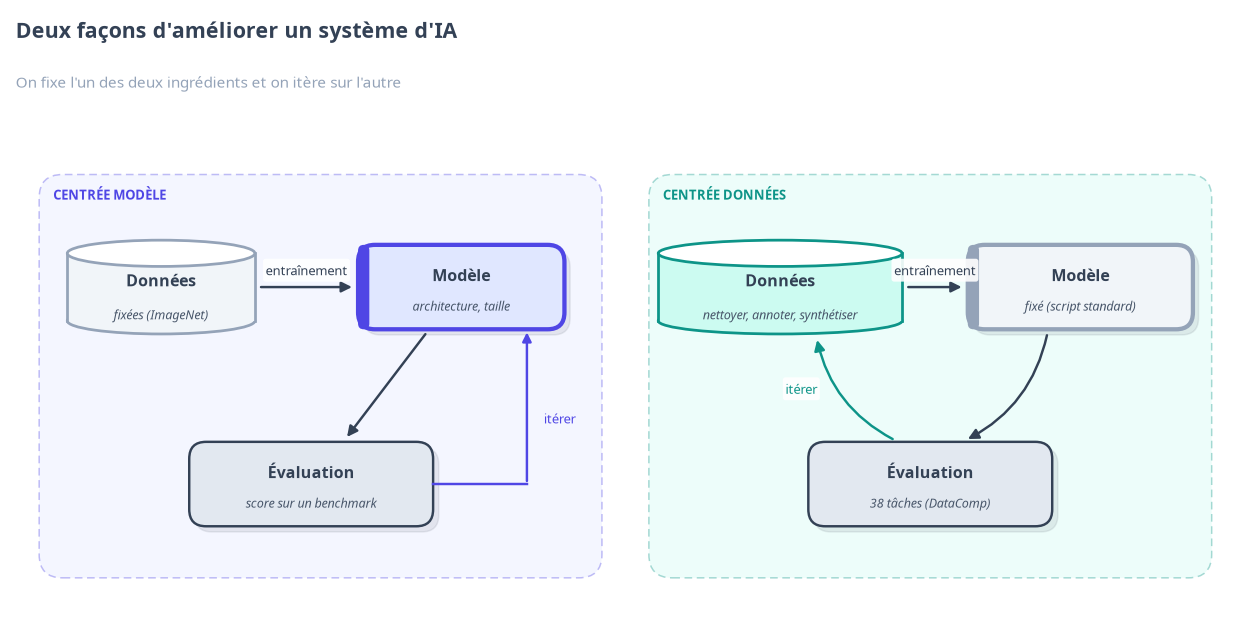

In [2]:
d = Diagram(13, 5.4, title="Deux façons d'améliorer un système d'IA",
            subtitle="On fixe l'un des deux ingrédients et on itère sur l'autre")
d.group(0.3, 0.3, 6.3, 4.6, "centrée modèle", color=INDIGO)
d.box("D1", 1.6, 3.4, "Données", sub="fixées (ImageNet)", color=GRAY, kind="db", w=2.0, h=1.0)
d.box("M1", 4.8, 3.4, "Modèle", sub="architecture, taille", color=INDIGO, kind="model", w=2.2)
d.box("E1", 3.2, 1.3, "Évaluation", sub="score sur un benchmark", color=SLATE, w=2.6)
d.arrow("D1", "M1", "entraînement")
d.arrow("M1", "E1")
d.line([(4.5, 1.3), (5.5, 1.3), (5.5, 2.95)], color=INDIGO, style="solid", lw=1.6)
d.note(5.85, 2.0, "itérer", color=INDIGO, fontsize=8.5, style="normal")
d.group(6.8, 0.3, 12.8, 4.6, "centrée données", color=TEAL)
d.box("M2", 11.4, 3.4, "Modèle", sub="fixé (script standard)", color=GRAY, kind="model", w=2.4)
d.box("D2", 8.2, 3.4, "Données", sub="nettoyer, annoter, synthétiser", color=TEAL, kind="db", w=2.6, h=1.0)
d.box("E2", 9.8, 1.3, "Évaluation", sub="38 tâches (DataComp)", color=SLATE, w=2.6)
d.arrow("D2", "M2", "entraînement")
d.arrow("M2", "E2", rad=-0.25)
d.arrow("E2", "D2", "itérer", color=TEAL, rad=-0.25, label_offset=(-0.45, 0.1))
d.show()

Le livre souligne que cette dichotomie guide la recherche mais qu'en pratique les
progrès viennent des deux. Pour un ingénieur d'application, en revanche, le levier
« données » est souvent le seul disponible : on ne modifie pas l'architecture de Qwen ou
de Llama, mais on choisit **ce qu'on lui montre**.

> **À retenir.** L'IA centrée sur les données cherche le meilleur jeu de données à
> modèle fixé. Comme les modèles de base sont largement partagés, les données sont
> devenues le principal facteur de différenciation, et un métier à part entière.

## 2. Quelles données pour quel entraînement ? (section *Data Curation*)

Les données à collecter dépendent de **ce que l'on veut apprendre au modèle**, donc de
la phase d'entraînement. Le livre distingue quatre formats :

| Phase | Format d'un exemple | Unité de quantité |
|---|---|---|
| Affinage auto-supervisé | une séquence de texte | tokens |
| Affinage sur instructions (SFT) | (instruction, réponse) | exemples |
| Affinage par préférences | (instruction, réponse gagnante, réponse perdante) | comparaisons |
| Modèle de récompense | idem, ou ((instruction, réponse), score) | exemples notés |

Le chapitre se concentre sur les données de **post-entraînement**, les plus utiles aux
développeurs d'applications. Voici un enregistrement de chaque type.

In [3]:
exemples = {
    "auto-supervisé": {"text": "Le contrat de bail est conclu pour une durée de trois ans..."},
    "SFT": {"instruction": "Résume ce bail en une phrase.",
            "response": "Bail de trois ans, loyer mensuel de 900 euros, préavis de trois mois."},
    "préférence": {"instruction": "Résume ce bail en une phrase.",
                   "chosen": "Bail de trois ans, loyer de 900 euros par mois.",
                   "rejected": "Ce document est un bail. Il contient des clauses."},
    "récompense": {"instruction": "Résume ce bail en une phrase.",
                   "response": "Ce document est un bail.", "score": 2},
}
pd.DataFrame({k: [str(v)] for k, v in exemples.items()}).T.rename(columns={0: "exemple (dict JSON)"})

,exemple (dict JSON)
auto-supervisé,{'text': 'Le contrat de bail est conclu pour une durée de trois ans...'}
SFT,"{'instruction': 'Résume ce bail en une phrase.', 'response': 'Bail de trois ans, loyer..."
préférence,"{'instruction': 'Résume ce bail en une phrase.', 'chosen': 'Bail de trois ans, loyer d..."
récompense,"{'instruction': 'Résume ce bail en une phrase.', 'response': 'Ce document est un bail...."


### Comportements complexes : chaîne de pensée et usage d'outils

Les données d'entraînement doivent **montrer le comportement voulu**. C'est facile pour
une réponse courte, beaucoup plus coûteux pour deux comportements complexes :

- **la chaîne de pensée** (CoT, chapitre 5) : pour qu'un modèle apprenne à raisonner pas
  à pas, ses données doivent contenir des réponses détaillées. Le livre cite des travaux
  où l'ajout de telles réponses dans l'affinage double presque l'exactitude sur certaines
  tâches de raisonnement. Mais écrire un raisonnement complet coûte bien plus cher
  qu'écrire la réponse finale ;
- **l'usage d'outils** : les experts humains oublient d'expliciter des étapes et, surtout,
  ce qui est efficace pour un humain (cliquer dans un navigateur) ne l'est pas pour un
  modèle (appeler une API). D'où le recours à la simulation et à la synthèse (cours 2).
  Ces données exigent aussi des formats spéciaux : Llama 3 utilise des en-têtes qui
  indiquent la source et la destination de chaque message (utilisateur, interpréteur
  de code...).

Mesurons le surcoût d'annotation de la chaîne de pensée en tokens, sur un exemple de
notre cru, avec le tokenizer de Qwen2.5.

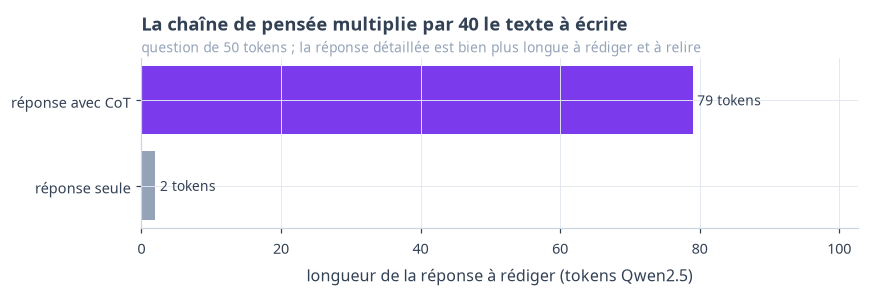

In [4]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(llm.SMALL)
question = ("Un cinéma compte 120 places. 47 spectateurs entrent à 20 h, 18 sortent à l'entracte "
            "et 25 arrivent ensuite. Combien de places restent libres ?")
sans_cot = "64"
avec_cot = ("Au départ, 47 spectateurs sont dans la salle. À l'entracte, 18 sortent : 47 - 18 = 29. "
            "Puis 25 arrivent : 29 + 25 = 54 spectateurs. Il reste donc 120 - 54 = 66 places libres.")
n_q, n_a, n_c = (len(tok(t)["input_ids"]) for t in (question, sans_cot, avec_cot))

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(["réponse seule", "réponse avec CoT"], [n_a, n_c], color=[GRAY, VIOLET])
annotate_bars(ax, "{:.0f} tokens")
ax.set_xlabel("longueur de la réponse à rédiger (tokens Qwen2.5)")
titre(ax, f"La chaîne de pensée multiplie par {n_c / n_a:.0f} le texte à écrire",
      f"question de {n_q} tokens ; la réponse détaillée est bien plus longue à rédiger et à relire")
ax.set_xlim(0, n_c * 1.3)
finish(fig)
plt.show()

Remarquez que la « réponse seule » ci-dessus (64) est **fausse** : 120 - 54 = 66. La
réponse détaillée, elle, se vérifie ligne à ligne. C'est un argument supplémentaire en
faveur des données CoT : elles sont plus faciles à **contrôler**, pour un annotateur
comme pour un vérificateur automatique.

### Un tour ou plusieurs ? Ajouter ou retirer ?

- Les données **à un tour** apprennent à répondre à une instruction isolée ; les données
  **multi-tours** apprennent à mener une tâche (clarifier l'intention, intégrer une
  correction). Elles sont plus rares car il faut des scénarios dédiés.
- La curation sert aussi à **désapprendre** : si un assistant ajoute des réécritures non
  sollicitées quand on lui demande seulement de vérifier un fait, on cherche les exemples
  d'entraînement qui montrent ce comportement, on les **retire**, et l'on en ajoute qui
  montrent le comportement attendu.

> **À retenir.** Le format des données découle de la phase d'entraînement : séquences,
> paires (instruction, réponse), triplets de préférence ou exemples notés. Les
> comportements complexes (raisonnement, outils, multi-tours) coûtent beaucoup plus cher à
> annoter, ce qui pousse vers la synthèse.

## 3. Qualité des données (section *Data Quality*)

**Le constat.** Peu de données de grande qualité battent souvent beaucoup de données
bruitées. Le livre cite les créateurs de Yi (10 000 instructions soignées valent mieux
que des centaines de milliers d'instructions bruitées) et LIMA (1 000 exemples
soigneusement choisis suffisent à rendre un Llama 65B compétitif, avec une robustesse
moindre que les modèles de production).

**Qu'est-ce qu'une donnée de qualité ?** Le livre retient six caractéristiques :

| Critère | Question à se poser | Exemple de défaut |
|---|---|---|
| **Pertinente** | L'exemple concerne-t-il la tâche ? | jurisprudence du XIXe siècle pour du droit actuel |
| **Alignée sur la tâche** | L'annotation fait-elle ce que la tâche exige ? | réponse longue alors qu'on veut de la concision |
| **Cohérente** | Deux annotateurs donneraient-ils la même chose ? | une note de 3 qui vaut un 4 ailleurs |
| **Bien formatée** | Le format est-il celui attendu par le modèle ? | balises HTML, espaces parasites |
| **Suffisamment unique** | Y a-t-il des doublons ? | le même exemple répété cent fois |
| **Conforme** | Respecte-t-elle lois et politiques internes ? | données personnelles (PII) |

Le livre préfère « alignée » à « exacte » : selon la tâche, la réponse attendue n'est pas
toujours la plus exacte (créativité, concision...). Les critères « bien formatée » et
« unique » sont traités au cours 3 ; ici, nous étudions la **cohérence**, via le bruit
d'étiquetage.

### Le petit monde expérimental

Quatre classes (pensez à quatre intentions d'utilisateur), chacune formée de trois
sous-populations (trois façons d'exprimer cette intention), en dimension 10. Le jeu de
test, propre, est tiré autour des mêmes centres.

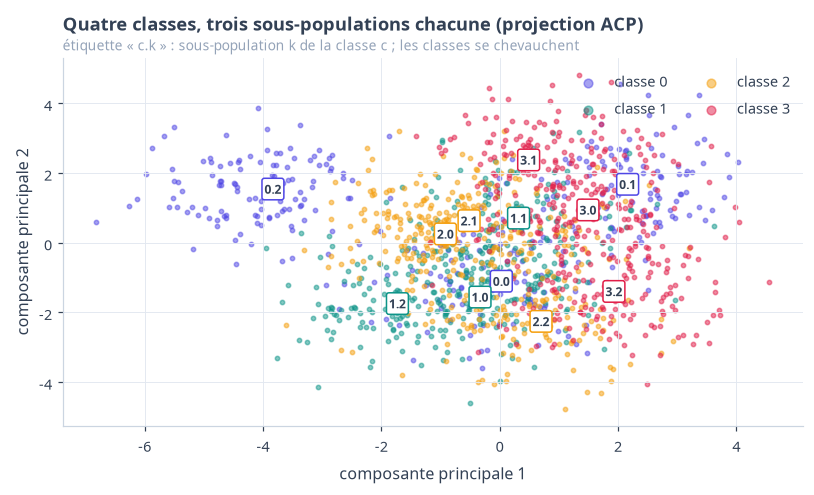

In [5]:
K, S, DIM, SEP = 4, 3, 10, 1.0
X, y, s, centres = d8.make_subpop_data(8000, n_classes=K, n_subpops=S, dim=DIM, sep=SEP, seed=0)
Xt, yt, st, _ = d8.make_subpop_data(3000, n_classes=K, n_subpops=S, dim=DIM, sep=SEP, seed=1, centers=centres)


def score(Xa, ya):
    """Exactitude sur le jeu de test propre d'un SVM (noyau RBF) entraîné sur (Xa, ya)."""
    return SVC().fit(Xa, ya).score(Xt, yt)


from sklearn.decomposition import PCA

P = PCA(2, random_state=0).fit(X)
Z = P.transform(X[:1500])
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for k in range(K):
    m = y[:1500] == k
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, color=COLORS[k], label=f"classe {k}")
Cz = P.transform(centres)
for g, (cx, cy) in enumerate(Cz):
    ax.text(cx, cy, f"{g // S}.{g % S}", fontsize=8, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COLORS[g // S]))
ax.set_xlabel("composante principale 1"); ax.set_ylabel("composante principale 2")
titre(ax, "Quatre classes, trois sous-populations chacune (projection ACP)",
      "étiquette « c.k » : sous-population k de la classe c ; les classes se chevauchent")
ax.legend(loc="upper right", ncol=2, markerscale=2)
finish(fig)
plt.show()

### Deux sortes de bruit

On corrompt une fraction $\varepsilon$ des étiquettes d'entraînement de deux façons :

- **bruit symétrique** : la mauvaise étiquette est tirée au hasard parmi les $K-1$ autres
  (erreurs d'inattention) ;
- **bruit systématique** : toutes les erreurs vont vers la même classe (un annotateur qui
  a mal compris une consigne, ou une consigne ambiguë).

**Petite démonstration.** Avec un bruit symétrique, pour un point $x$ de vraie classe
$c$, l'étiquette observée vaut $c$ avec probabilité $1-\varepsilon$ et chaque autre
classe avec probabilité $\varepsilon/(K-1)$. La classe observée la plus probable reste
$c$ tant que
$$1 - \varepsilon > \frac{\varepsilon}{K-1} \iff \varepsilon < \frac{K-1}{K} = 75\,\% \text{ pour } K = 4.$$
Le classifieur idéal (de Bayes) est donc **inchangé** : avec assez de données, le bruit
symétrique coûte surtout de **l'efficacité statistique**. Le bruit systématique, lui,
**déplace les frontières de décision** vers la classe cible : plus de données n'y change
rien.

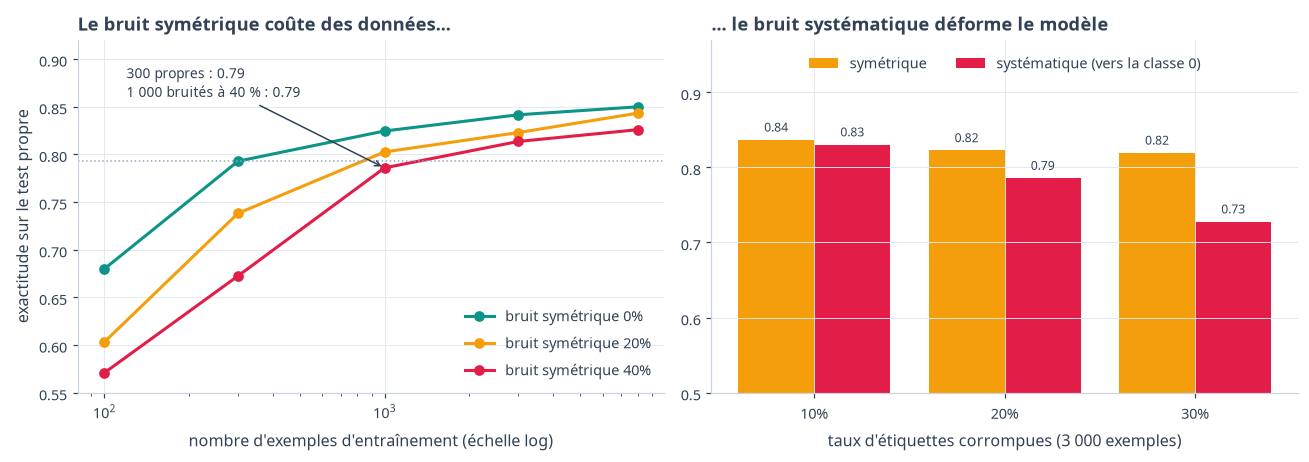

In [6]:
tailles = [100, 300, 1000, 3000, 8000]
taux = [0.0, 0.2, 0.4]
res = {r: [score(X[:n], d8.flip_labels(y, r, K, seed=1)[:n]) for n in tailles] for r in taux}
res_sys = {r: score(X[:3000], d8.flip_labels(y, r, K, seed=1, target=0)[:3000]) for r in [0.1, 0.2, 0.3]}
res_sym = {r: score(X[:3000], d8.flip_labels(y, r, K, seed=1)[:3000]) for r in [0.1, 0.2, 0.3]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
for r, c in zip(taux, [TEAL, AMBER, ROSE]):
    ax.plot(tailles, res[r], "o-", color=c, label=f"bruit symétrique {r:.0%}")
ax.set_xscale("log")
ax.set_xlabel("nombre d'exemples d'entraînement (échelle log)")
ax.set_ylabel("exactitude sur le test propre")
ax.set_title("Le bruit symétrique coûte des données...")
ax.axhline(res[0.0][1], color=GRAY, ls=":", lw=1)
ax.annotate(f"300 propres : {res[0.0][1]:.2f}\n1 000 bruités à 40 % : {res[0.4][2]:.2f}",
            xy=(1000, res[0.4][2]), xytext=(120, 0.86), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=SLATE))
ax.set_ylim(0.55, 0.92)
ax.legend(loc="lower right")
ax = axes[1]
xs = np.arange(3)
ax.bar(xs - 0.2, list(res_sym.values()), 0.4, color=AMBER, label="symétrique")
ax.bar(xs + 0.2, list(res_sys.values()), 0.4, color=ROSE, label="systématique (vers la classe 0)")
annotate_bars(ax, "{:.2f}", fontsize=8)
ax.set_xticks(xs, [f"{r:.0%}" for r in res_sym])
ax.set_xlabel("taux d'étiquettes corrompues (3 000 exemples)")
ax.set_ylim(0.5, 0.97)
ax.set_title("... le bruit systématique déforme le modèle")
ax.legend(loc="upper center", ncol=2)
finish(fig)
plt.show()

Les résultats confirment l'analyse :

- avec un bruit symétrique, les courbes finissent par rejoindre la courbe propre, mais il
  faut **plus d'exemples** pour y arriver : environ 300 exemples propres font aussi bien
  que 1 000 exemples bruités à 40 %. C'est la version miniature du message de LIMA et de
  Yi : la qualité **remplace** de la quantité ;
- avec un bruit systématique, l'écart se creuse vite avec $\varepsilon$ : le modèle
  apprend la consigne mal comprise. C'est pourquoi le livre insiste sur la **cohérence**
  et sur les **consignes d'annotation** (section 6).

> **À retenir.** Six critères définissent une donnée de qualité : pertinente, alignée,
> cohérente, bien formatée, unique, conforme. Le bruit aléatoire se paie en quantité de
> données ; le bruit systématique (consigne mal comprise, biais d'annotateur) se paie en
> qualité du modèle, et aucune quantité ne le compense.

## 4. Couverture et diversité (section *Data Coverage*)

**Le problème.** Les utilisateurs réels formulent leurs demandes de mille façons :
instructions longues ou courtes, avec fautes de frappe, dans plusieurs langues... Les
données doivent **couvrir** ces usages, d'où le terme équivalent de **diversité**. Les
axes de diversité dépendent de l'application : un traducteur français-anglais n'a pas
besoin de diversité de langues mais de sujets et de styles ; un assistant d'achat
mondial a besoin de diversité linguistique et culturelle.

### Expérience : même budget, couverture croissante

On garde **1 000 exemples** mais on fait varier le nombre de sous-populations
représentées dans l'entraînement (une, deux ou trois « façons de demander » par classe).
Le test, lui, contient toutes les sous-populations, comme le trafic réel.

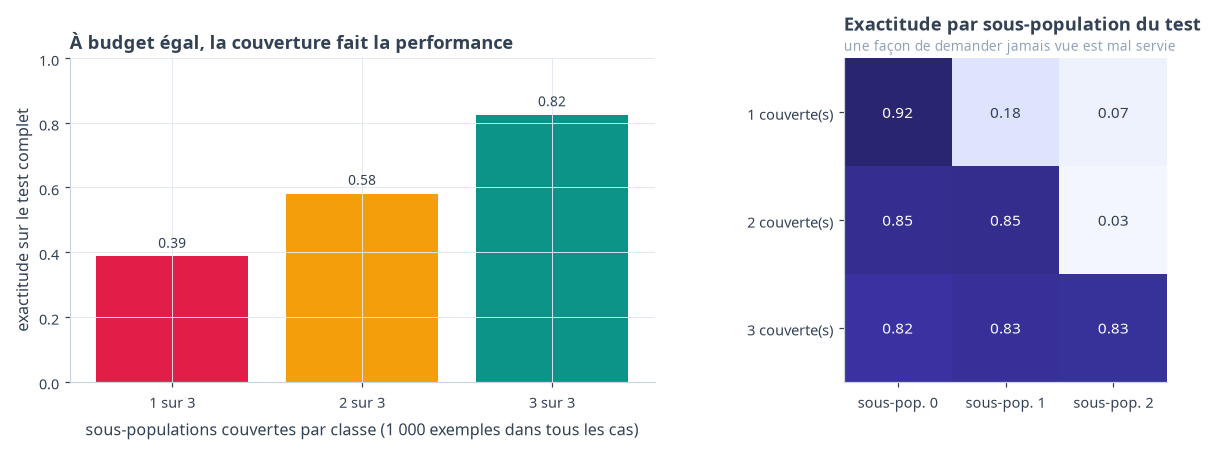

In [7]:
cov = {}
for k in range(1, S + 1):
    m = (s % S) < k
    sc = score(X[m][:1000], y[m][:1000])
    per_group = [(SVC().fit(X[m][:1000], y[m][:1000]).predict(Xt[st % S == g]) == yt[st % S == g]).mean()
                 for g in range(S)]
    cov[k] = (sc, per_group)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.bar([f"{k} sur {S}" for k in cov], [v[0] for v in cov.values()], color=[ROSE, AMBER, TEAL])
annotate_bars(ax, "{:.2f}")
ax.set_xlabel("sous-populations couvertes par classe (1 000 exemples dans tous les cas)")
ax.set_ylabel("exactitude sur le test complet")
ax.set_ylim(0, 1)
ax.set_title("À budget égal, la couverture fait la performance")
ax = axes[1]
M = np.array([v[1] for v in cov.values()])
im = ax.imshow(M, cmap="aie_seq", vmin=0, vmax=1)
for i in range(S):
    for j in range(S):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="white" if M[i, j] > 0.6 else SLATE)
ax.set_xticks(range(S), [f"sous-pop. {g}" for g in range(S)])
ax.set_yticks(range(S), [f"{k} couverte(s)" for k in cov])
ax.grid(False)
titre(ax, "Exactitude par sous-population du test", "une façon de demander jamais vue est mal servie")
finish(fig)
plt.show()

Une sous-population absente de l'entraînement est traitée presque au hasard (environ
0,25 pour quatre classes, parfois pire), même si elle appartient à une classe
« connue ». Le livre cite le même phénomène à grande échelle : les gains de Llama 3 sur
Llama 2 viennent surtout de la qualité et de la **diversité** des données, et
l'affinage de Flan s'améliore fortement quand le nombre de **tâches** passe de 9 à 282.

### Le mélange de données de Llama 3

Le tableau 8-1 du livre donne la répartition par domaine des données de Llama 3 selon la
phase. Représentons-le.

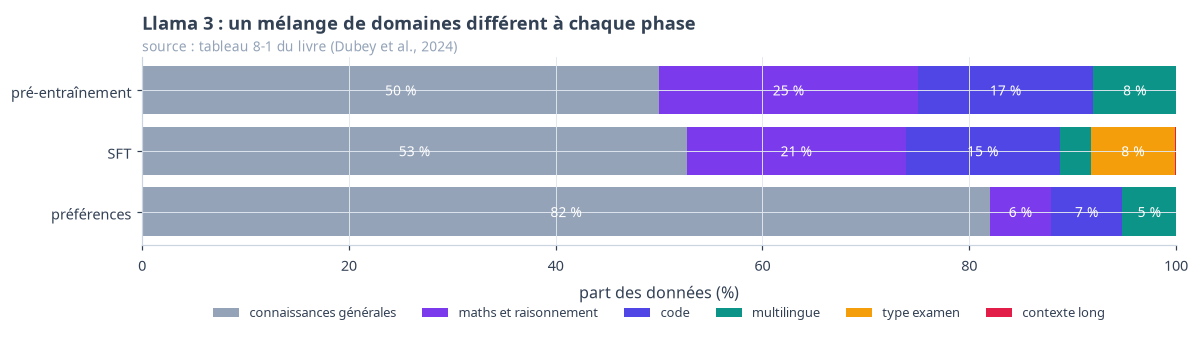

In [8]:
mix = pd.DataFrame(
    {"pré-entraînement": [50, 25, 17, 8, 0, 0],
     "SFT": [52.66, 21.19, 14.89, 3.01, 8.14, 0.11],
     "préférences": [81.99, 5.89, 6.93, 5.19, 0, 0]},
    index=["connaissances générales", "maths et raisonnement", "code", "multilingue",
           "type examen", "contexte long"])
fig, ax = plt.subplots(figsize=(11, 3.4))
left = np.zeros(3)
for (dom, row), c in zip(mix.iterrows(), [GRAY, VIOLET, INDIGO, TEAL, AMBER, ROSE]):
    ax.barh(mix.columns, row.values, left=left, color=c, label=dom)
    for i, v in enumerate(row.values):
        if v >= 5:
            ax.text(left[i] + v / 2, i, f"{v:.0f} %", ha="center", va="center", color="white", fontsize=9)
    left += row.values
ax.invert_yaxis()
ax.set_xlabel("part des données (%)")
titre(ax, "Llama 3 : un mélange de domaines différent à chaque phase",
      "source : tableau 8-1 du livre (Dubey et al., 2024)")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.25), fontsize=8.5)
finish(fig)
plt.show()

Deux observations du livre : en pré-entraînement et en SFT, maths, raisonnement et code
pèsent près de la moitié des données, bien plus que leur part sur le web, car ces données
améliorent fortement le raisonnement ; en affinage par préférences, cette part tombe à
13 % pour refléter la distribution réelle des préférences des utilisateurs. Pour choisir
un mélange, on peut soit **imiter l'usage réel** de l'application, soit **expérimenter**
(Meta entraîne de petits modèles sur chaque mélange candidat et extrapole par lois
d'échelle ; l'exercice 8.5 reproduit ce principe).

### Mesurer la diversité d'un jeu d'instructions

Comment chiffrer la diversité ? Deux mesures complémentaires :

- **distinct-$n$** : proportion de $n$-grammes de mots distincts (diversité de surface) ;
- **score de Vendi** : à partir de la matrice $K$ de similarité cosinus entre embeddings
  ($n \times n$), on calcule les valeurs propres $\lambda_i$ de $K/n$ et
  $$\mathrm{VS} = \exp\Big(-\sum_i \lambda_i \log \lambda_i\Big).$$
  C'est l'exponentielle de l'entropie du spectre : VS vaut 1 si tous les exemples sont
  identiques, $n$ s'ils sont tous orthogonaux. On le lit comme un **nombre effectif
  d'exemples distincts** (diversité de sens).

Comparons trois jeux de 20 instructions : nos instructions rédigées à la main sur des
sujets variés, des instructions produites par **un seul gabarit**, et des reformulations
d'**une même demande**.

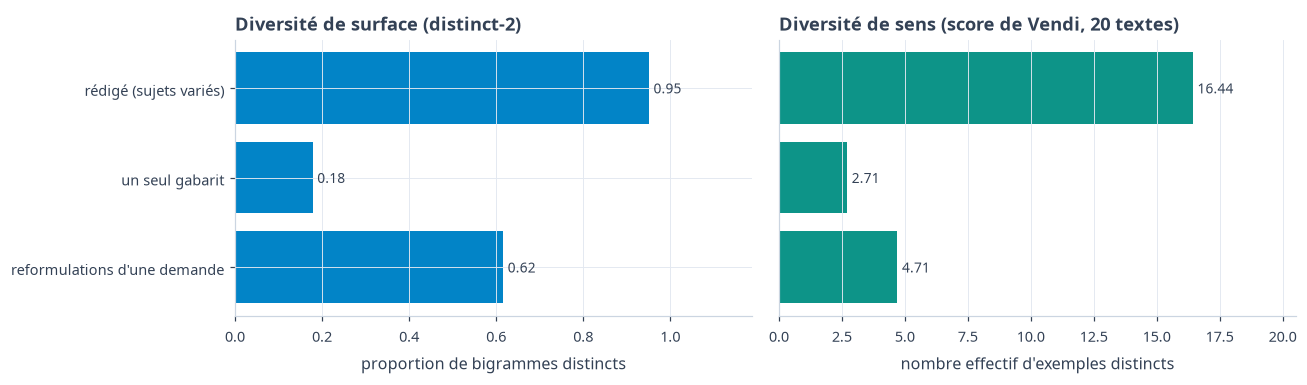

,distinct-2,Vendi,distance cosinus moy.
jeu,,,
rédigé (sujets variés),0.951,16.438,0.891
un seul gabarit,0.179,2.708,0.262
reformulations d'une demande,0.616,4.705,0.398


In [9]:
manuel = [p[2] for p in d8.BASE_PAIRS[:20]]
gabarit = [d8.fill_template("Donne-moi une recette de {plat} pour {n} personnes.",
                            {"plat": ["crêpes", "lasagnes", "quiche", "soupe", "tarte", "risotto", "gratin"],
                             "n": ["deux", "quatre", "six", "huit"]}, rng) for _ in range(20)]
reformul = ["Comment réinitialiser mon mot de passe ?", "J'ai oublié mon mot de passe.",
            "Comment changer mon mot de passe ?", "Étapes pour réinitialiser un mot de passe.",
            "Je n'arrive plus à me connecter, mot de passe perdu.", "Où modifier mon mot de passe ?",
            "Mot de passe oublié, que faire ?", "Procédure de récupération du mot de passe ?",
            "Je veux un nouveau mot de passe.", "Réinitialisation du mot de passe impossible.",
            "Comment récupérer l'accès à mon compte ?", "Mon mot de passe ne fonctionne plus.",
            "Aide : mot de passe perdu.", "Changer le mot de passe de mon compte.",
            "Peut-on réinitialiser le mot de passe par SMS ?", "Lien de réinitialisation non reçu.",
            "Le mot de passe est refusé, pourquoi ?", "Comment sécuriser puis changer mon mot de passe ?",
            "Mot de passe expiré, comment le renouveler ?", "Récupérer mon mot de passe oublié."]
jeux = {"rédigé (sujets variés)": manuel, "un seul gabarit": gabarit, "reformulations d'une demande": reformul}
rows = []
for nom, txts in jeux.items():
    E = llm.embed(txts, llm.EMBED_MULTI)
    rows.append({"jeu": nom, "distinct-2": d8.distinct_n(txts, 2), "Vendi": d8.vendi_score(E),
                 "distance cosinus moy.": d8.mean_pairwise_distance(E)})
div = pd.DataFrame(rows).set_index("jeu")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, col, c in zip(axes, ["distinct-2", "Vendi"], [SKY, TEAL]):
    ax.barh(div.index, div[col], color=c)
    annotate_bars(ax, "{:.2f}")
    ax.invert_yaxis()
    ax.set_xlim(0, div[col].max() * 1.25)
axes[0].set_title("Diversité de surface (distinct-2)")
axes[0].set_xlabel("proportion de bigrammes distincts")
axes[1].set_title("Diversité de sens (score de Vendi, 20 textes)")
axes[1].set_xlabel("nombre effectif d'exemples distincts")
axes[1].set_yticks([])
finish(fig)
plt.show()
div.round(3)

Les deux mesures ne disent pas la même chose. Les reformulations ont une diversité de
**surface** honorable (les mots changent) mais un score de Vendi faible (le sens est le
même) ; le jeu à gabarit unique est pauvre sur les deux plans. Le jeu rédigé couvre de
vrais sujets différents et obtient le meilleur score de Vendi. Attention toutefois : plus
de diversité n'est pas toujours mieux. Le livre cite *The Data Addition Dilemma*, où
l'ajout de données hétérogènes **dégrade** parfois les performances : la diversité doit
suivre les axes de **l'usage réel**, pas s'étendre au hasard.

> **À retenir.** La couverture (ou diversité) consiste à représenter toutes les façons
> dont les utilisateurs posent leurs problèmes. À budget égal, un jeu qui couvre toutes
> les sous-populations bat largement un jeu concentré. Distinct-$n$ mesure la diversité de
> surface, le score de Vendi la diversité de sens.

## 5. Quantité de données (section *Data Quantity*)

Combien d'exemples faut-il ? Le livre répond « autant demander combien d'argent il
faut » : de **un seul** exemple (expérience de Howard et Whitaker) à des **millions**.
Pour comparaison, Llama 3 a été pré-entraîné sur environ 16 000 milliards de tokens,
soit des milliards d'exemples de 2 000 tokens. Trois facteurs, en plus de la qualité et
de la diversité, déterminent le besoin :

- **la technique d'affinage** : l'affinage complet demande des ordres de grandeur de plus
  que les méthodes PEFT comme LoRA (quelques centaines à quelques milliers d'exemples
  suffisent souvent à LoRA ; des dizaines de milliers à des millions pour l'affinage
  complet) ;
- **la complexité de la tâche** : classer un sentiment demande moins que répondre sur des
  rapports financiers ;
- **le niveau du modèle de base** : plus il est proche de la cible, moins il faut
  d'exemples. Le guide d'affinage d'OpenAI montre qu'avec 100 exemples les modèles les
  plus avancés l'emportent nettement, alors qu'avec 550 000 exemples tous les modèles se
  valent. Avec beaucoup de données, un modèle trop pré-entraîné peut même s'**ossifier**
  (ses poids s'adaptent mal), surtout s'il est petit.

### La courbe d'apprentissage et sa loi de puissance

Le conseil pratique du livre : commencer par un petit jeu soigné (environ 50 exemples),
vérifier que l'affinage aide, puis entraîner sur 25 %, 50 % et 100 % des données pour
**tracer la courbe** et extrapoler. Empiriquement, l'erreur décroît souvent comme une
loi de puissance :
$$\mathrm{err}(n) \approx a\, n^{-b} + c,$$
où $c$ est l'erreur **irréductible** (bruit, ambiguïté de la tâche) et $b$ l'exposant
d'apprentissage. Le gain marginal d'un exemple supplémentaire vaut
$\left|\frac{d\,\mathrm{err}}{dn}\right| = a b\, n^{-b-1}$ : il décroît plus vite que
$1/n$, d'où les **rendements décroissants** (les 1 000 premiers exemples rapportent
beaucoup plus que les 1 000 suivants).

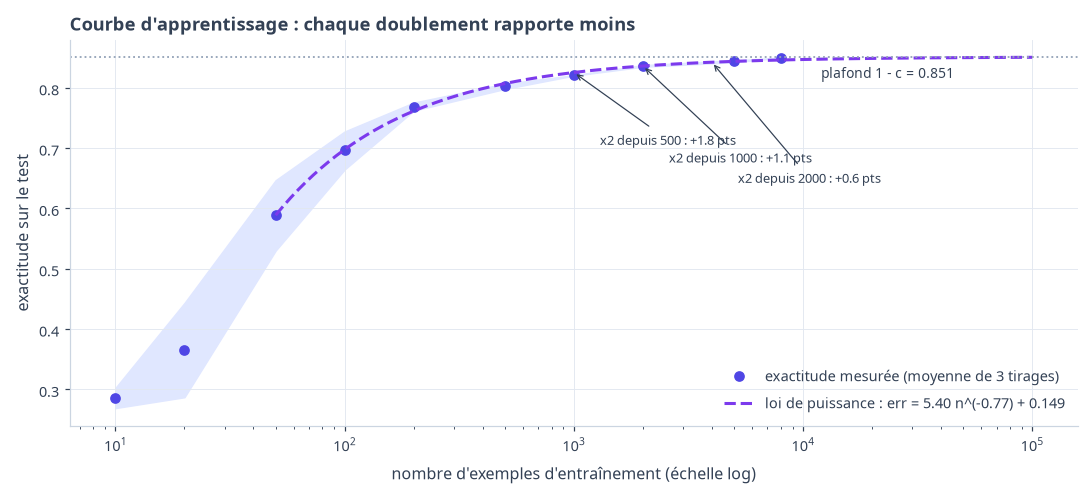

In [10]:
tailles = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 8000])
moy, ect = d8.learning_curve(X, y, Xt, yt, tailles, n_repeats=3, model_factory=SVC)
a, b, c = d8.fit_power_law(tailles[2:], 1 - moy[2:])
grille = np.logspace(np.log10(50), np.log10(1e5), 200)

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(tailles, moy - ect, moy + ect, color=LIGHT[INDIGO])
ax.plot(tailles, moy, "o", color=INDIGO, label="exactitude mesurée (moyenne de 3 tirages)")
ax.plot(grille, 1 - d8.power_law(grille, a, b, c), color=VIOLET, ls="--",
        label=f"loi de puissance : err = {a:.2f} n^(-{b:.2f}) + {c:.3f}")
ax.axhline(1 - c, color=GRAY, ls=":", lw=1.2)
ax.text(1.2e4, 1 - c - 0.035, f"plafond 1 - c = {1 - c:.3f}", color=SLATE, fontsize=9)
for n0 in [500, 1000, 2000]:
    gain = (d8.power_law(n0, a, b, c) - d8.power_law(2 * n0, a, b, c))
    ax.annotate(f"x2 depuis {n0} : +{gain * 100:.1f} pts", xy=(2 * n0, 1 - d8.power_law(2 * n0, a, b, c)),
                xytext=(2 * n0 * 1.3, 1 - d8.power_law(2 * n0, a, b, c) - 0.12 - 0.04 * np.log2(n0 / 500)),
                fontsize=8.5, arrowprops=dict(arrowstyle="->", color=SLATE, lw=0.8))
ax.set_xscale("log")
ax.set_xlabel("nombre d'exemples d'entraînement (échelle log)")
ax.set_ylabel("exactitude sur le test")
ax.set_title("Courbe d'apprentissage : chaque doublement rapporte moins")
ax.legend(loc="lower right")
finish(fig)
plt.show()

On peut inverser la loi pour estimer le nombre d'exemples nécessaire à une erreur cible
$e^\star > c$ :
$$n^\star = \left(\frac{a}{e^\star - c}\right)^{1/b}.$$
Combinée au **budget**, elle aide à décider. Le livre prend l'exemple d'un budget
d'annotation de 10 000 dollars à 2 dollars l'exemple : au plus 5 000 exemples, et chaque
dollar dépensé en données en moins est un dollar disponible pour le calcul.

In [11]:
cibles = [0.80, 0.82, 0.84, 0.85]
tab = []
for acc in cibles:
    e = 1 - acc
    n_star = (a / (e - c)) ** (1 / b) if e > c else np.inf
    tab.append({"exactitude visée": f"{acc:.2f}", "exemples nécessaires": f"{n_star:,.0f}".replace(",", " "),
                "coût à 2 $ l'exemple": f"{2 * n_star:,.0f} $".replace(",", " ") if np.isfinite(n_star) else "inatteignable"})
pd.DataFrame(tab)

,exactitude visée,exemples nécessaires,coût à 2 $ l'exemple
0,0.80,417,835 $
1,0.82,797,1 593 $
2,0.84,3 073,6 146 $
3,0.85,80 509,161 018 $


Le coût explose à l'approche du plafond $1-c$ : passer de 0,82 à 0,84 coûte bien plus
que de 0,80 à 0,82. Au-delà du plafond, c'est **la qualité** (réduire $c$ : consignes,
nettoyage) ou **le modèle** qu'il faut changer, pas la quantité.

**Réduire le besoin en données de haute qualité.** Le livre propose d'affiner d'abord sur
des données moins chères puis sur les données cibles : auto-supervisé puis supervisé
(documents juridiques puis paires question-réponse), données voisines puis données
pertinentes (tweets puis avis produits), données synthétiques puis réelles (plus délicat
à réussir).

> **À retenir.** Tracer la courbe d'apprentissage sur des sous-ensembles (25, 50, 100 %)
> est le meilleur outil pour décider d'acheter des données. Les rendements sont
> décroissants ($\mathrm{err} \approx a n^{-b} + c$) et le plafond $c$ ne se franchit pas
> avec plus d'exemples du même type. Si 50 à 100 exemples bien faits n'apportent aucune
> amélioration, vérifiez les hyperparamètres et les prompts avant d'en acheter plus.

## 6. Acquisition et annotation (section *Data Acquisition and Annotation*)

### Sources et entonnoir de constitution

L'acquisition combine plusieurs canaux : données publiques, données achetées,
annotation, synthèse. La source la plus précieuse reste **l'application elle-même** :
un **volant d'inertie des données** (« data flywheel ») transforme l'usage en
données parfaitement pertinentes, qui améliorent le produit, qui attire plus d'usage
(le recueil des retours utilisateurs est l'objet du chapitre 10).

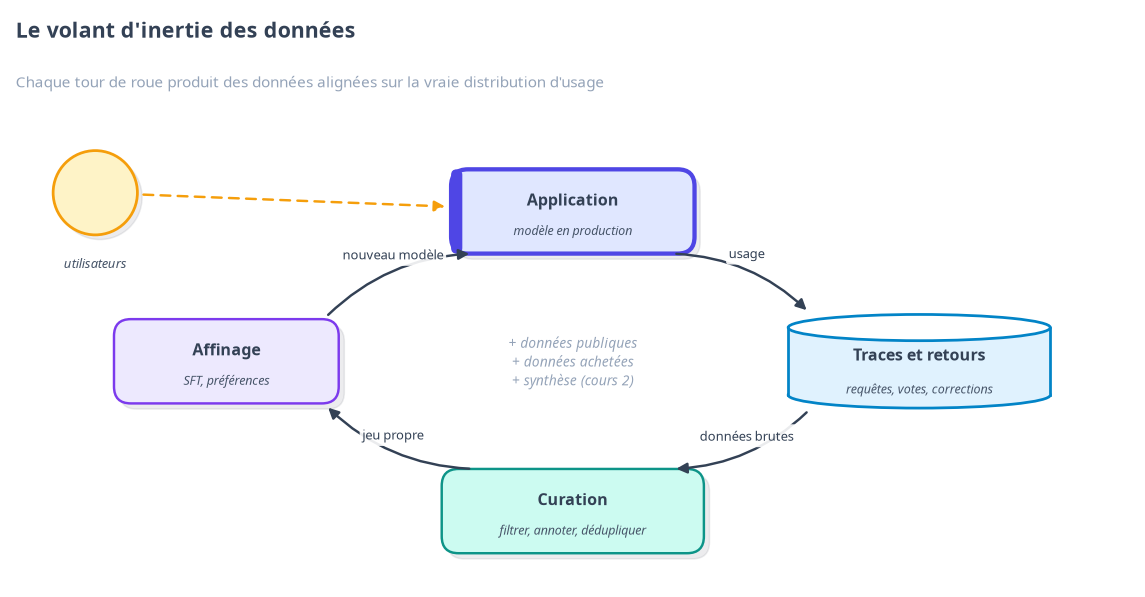

In [12]:
d = Diagram(12, 5.2, title="Le volant d'inertie des données",
            subtitle="Chaque tour de roue produit des données alignées sur la vraie distribution d'usage")
d.box("app", 6.0, 4.0, "Application", sub="modèle en production", color=INDIGO, kind="model", w=2.6)
d.box("logs", 9.7, 2.4, "Traces et retours", sub="requêtes, votes, corrections", color=SKY, kind="db", w=2.8, h=1.0)
d.box("cur", 6.0, 0.8, "Curation", sub="filtrer, annoter, dédupliquer", color=TEAL, w=2.8)
d.box("ft", 2.3, 2.4, "Affinage", sub="SFT, préférences", color=VIOLET, w=2.4)
d.box("users", 0.9, 4.2, "", color=AMBER, kind="user", w=0.9)
d.note(0.9, 3.45, "utilisateurs", fontsize=8.5)
d.arrow("app", "logs", "usage", rad=-0.2)
d.arrow("logs", "cur", "données brutes", rad=-0.2)
d.arrow("cur", "ft", "jeu propre", rad=-0.2)
d.arrow("ft", "app", "nouveau modèle", rad=-0.2)
d.arrow("users", "app", style="dashed", color=AMBER)
d.note(6.0, 2.4, "+ données publiques\n+ données achetées\n+ synthèse (cours 2)", color=GRAY)
d.show()

Le livre déroule un exemple réaliste (et simplifié) de constitution d'un jeu
(instruction, réponse) : partir d'un jeu public de 10 000 exemples, retirer les
instructions médiocres, mettre de côté les réponses médiocres, réécrire ces réponses à la
main, puis combler un sujet manquant par synthèse et annotation. En pratique, on
reboucle souvent : consignes revues, réannotation, vérification des faits...

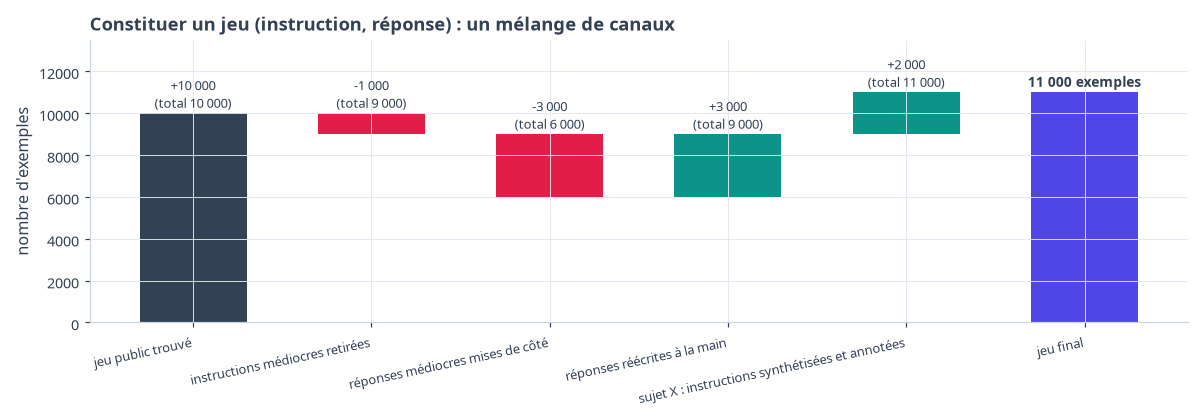

In [13]:
etapes = [("jeu public trouvé", +10000), ("instructions médiocres retirées", -1000),
          ("réponses médiocres mises de côté", -3000), ("réponses réécrites à la main", +3000),
          ("sujet X : instructions synthétisées et annotées", +2000)]
fig, ax = plt.subplots(figsize=(11, 3.9))
total = 0
for i, (lab, delta) in enumerate(etapes):
    bas = total if delta > 0 else total + delta
    c = SLATE if i == 0 else (TEAL if delta > 0 else ROSE)
    ax.bar(i, abs(delta), bottom=bas, color=c, width=0.6)
    total += delta
    signe = "+" if delta > 0 else "-"
    ax.text(i, max(bas + abs(delta), total) + 250,
            f"{signe}{abs(delta):,}\n(total {total:,})".replace(",", " "), ha="center", fontsize=8.5)
ax.bar(len(etapes), total, color=INDIGO, width=0.6)
ax.text(len(etapes), total + 250, f"{total:,} exemples".replace(",", " "), ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(len(etapes) + 1), [e[0] for e in etapes] + ["jeu final"], fontsize=8.5)
ax.set_ylim(0, 13500)
ax.set_ylabel("nombre d'exemples")
ax.set_title("Constituer un jeu (instruction, réponse) : un mélange de canaux")
plt.setp(ax.get_xticklabels(), rotation=12, ha="right")
finish(fig)
plt.show()

Avant d'utiliser un jeu public, le livre recommande de **vérifier sa licence** (y compris
celle de ses sources) et de **ne jamais lui faire entièrement confiance** : il faut
l'inspecter comme n'importe quelle donnée brute (cours 3).

### Les consignes d'annotation

Annoter est difficile, mais **écrire les consignes** l'est encore plus : qu'est-ce qu'une
bonne réponse ? Une réponse peut-elle être exacte mais inutile ? Qu'est-ce qui sépare un
3 d'un 4 ? Le livre rapporte que des équipes (LinkedIn notamment) placent les consignes
parmi les étapes les plus difficiles de leur chaîne, et que ce sont **les mêmes** que
pour les données d'évaluation (chapitre 4). Voici un extrait de consigne bien construite
pour noter des réponses d'un assistant de support :

> **Note 1 à 5 de l'utilité d'une réponse.**
> - **5** : résout entièrement le problème, sans information superflue ni erreur.
> - **4** : résout le problème ; une information mineure manque ou est superflue.
> - **3** : partiellement utile ; l'utilisateur doit chercher ailleurs une étape clé.
> - **2** : hors sujet en grande partie, ou contient une erreur qui gênerait l'utilisateur.
> - **1** : faux, dangereux ou refus injustifié.
> - **Cas limites** : une réponse exacte mais trop longue est notée 4 au plus ; une réponse
>   qui invente une procédure est notée 1 même si elle est bien rédigée.
> - **Exemples** : trois réponses annotées par note, dont deux cas limites commentés.

### Mesurer l'accord inter-annotateurs

Une bonne consigne se mesure : si deux annotateurs indépendants donnent la même
étiquette, la consigne est claire. Mais l'**accord brut** $p_o$ (proportion d'items
étiquetés pareil) est trompeur, car une partie de l'accord est due au **hasard**. Le
**kappa de Cohen** corrige cet effet :
$$\kappa = \frac{p_o - p_e}{1 - p_e}, \qquad p_e = \sum_{j} p_{A}(j)\, p_{B}(j),$$
où $p_A(j)$ et $p_B(j)$ sont les fréquences de la catégorie $j$ chez chacun des deux
annotateurs : $p_e$ est l'accord attendu si les deux étiquetaient au hasard avec leurs
propres fréquences. $\kappa = 1$ : accord parfait ; $\kappa = 0$ : pas mieux que le
hasard. Pour une échelle ordinale (notes de 1 à 5), le **kappa pondéré** pénalise un
désaccord 1 contre 5 plus qu'un 4 contre 5 :
$\kappa_w = 1 - \frac{\sum_{ij} w_{ij} O_{ij}}{\sum_{ij} w_{ij} E_{ij}}$ avec par exemple
$w_{ij} = (i-j)^2/(k-1)^2$.

**Le piège de l'accord brut.** Prenons une tâche de modération où 95 % des messages sont
acceptables, et deux annotateurs qui répondent « acceptable » 95 % du temps **au hasard**
(sans lire le message).

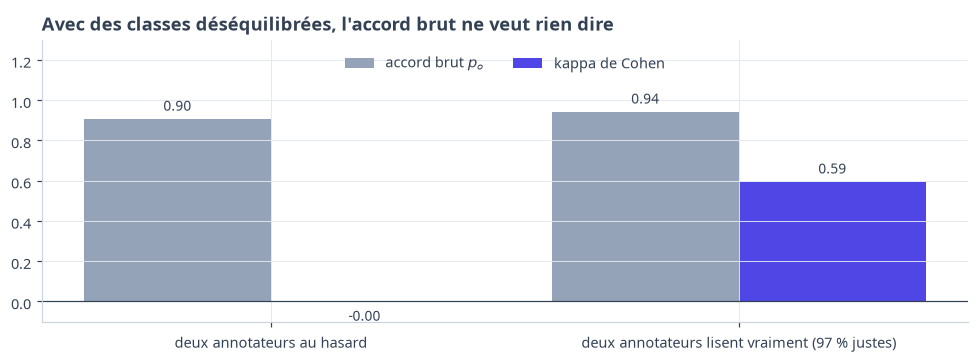

In [14]:
n = 2000
vrai = (rng.random(n) < 0.05).astype(int)  # 1 = message problématique (5 %)
ann_hasard_A = (rng.random(n) < 0.05).astype(int)
ann_hasard_B = (rng.random(n) < 0.05).astype(int)
ann_bon_A = np.where(rng.random(n) < 0.97, vrai, 1 - vrai)
ann_bon_B = np.where(rng.random(n) < 0.97, vrai, 1 - vrai)
cas = {"au hasard": (ann_hasard_A, ann_hasard_B), "lisent vraiment (97 % justes)": (ann_bon_A, ann_bon_B)}
fig, ax = plt.subplots(figsize=(9, 3.4))
lab, po, ka = [], [], []
for nom, (A, B) in cas.items():
    lab.append(nom); po.append(np.mean(A == B)); ka.append(d8.cohen_kappa(A, B))
xs = np.arange(2)
ax.bar(xs - 0.2, po, 0.4, color=GRAY, label="accord brut $p_o$")
ax.bar(xs + 0.2, ka, 0.4, color=INDIGO, label="kappa de Cohen")
annotate_bars(ax, "{:.2f}")
ax.set_xticks(xs, [f"deux annotateurs {l}" for l in lab])
ax.set_ylim(-0.1, 1.3)
ax.axhline(0, color=SLATE, lw=0.8)
ax.set_title("Avec des classes déséquilibrées, l'accord brut ne veut rien dire")
ax.legend(loc="upper center", ncol=2)
finish(fig)
plt.show()

Les annotateurs « au hasard » ont un accord brut d'environ 90 %, mais un kappa proche de
0 : ils ne font pas mieux que le hasard. Les annotateurs sérieux ont un accord brut à
peine supérieur, mais un kappa élevé. Le kappa se lit souvent avec la grille de Landis et
Koch : moins de 0,2 faible, 0,4 à 0,6 modéré, 0,6 à 0,8 substantiel, au-delà quasi
parfait.

### Plus de deux annotateurs : le kappa de Fleiss

Avec $m$ annotateurs par item, on compte $n_{ij}$, le nombre d'annotateurs ayant mis
l'item $i$ dans la catégorie $j$. L'accord sur l'item $i$ est la proportion de **paires
d'annotateurs** d'accord :
$$P_i = \frac{1}{m(m-1)} \sum_j n_{ij}(n_{ij} - 1), \qquad \bar P = \frac1N \sum_i P_i,$$
et l'accord attendu par hasard vaut $P_e = \sum_j p_j^2$ avec $p_j$ la proportion
globale de la catégorie $j$. Alors $\kappa_F = (\bar P - P_e)/(1 - P_e)$.

**Expérience : l'effet d'une consigne.** On simule 200 items notés de 1 à 5 par cinq
annotateurs, avec une consigne **vague** (chacun se trompe souvent, et deux annotateurs
ont un biais systématique : l'un note généreusement, l'autre sévèrement) puis avec une
consigne **claire** (erreurs rares, biais corrigés par les cas limites et les exemples).

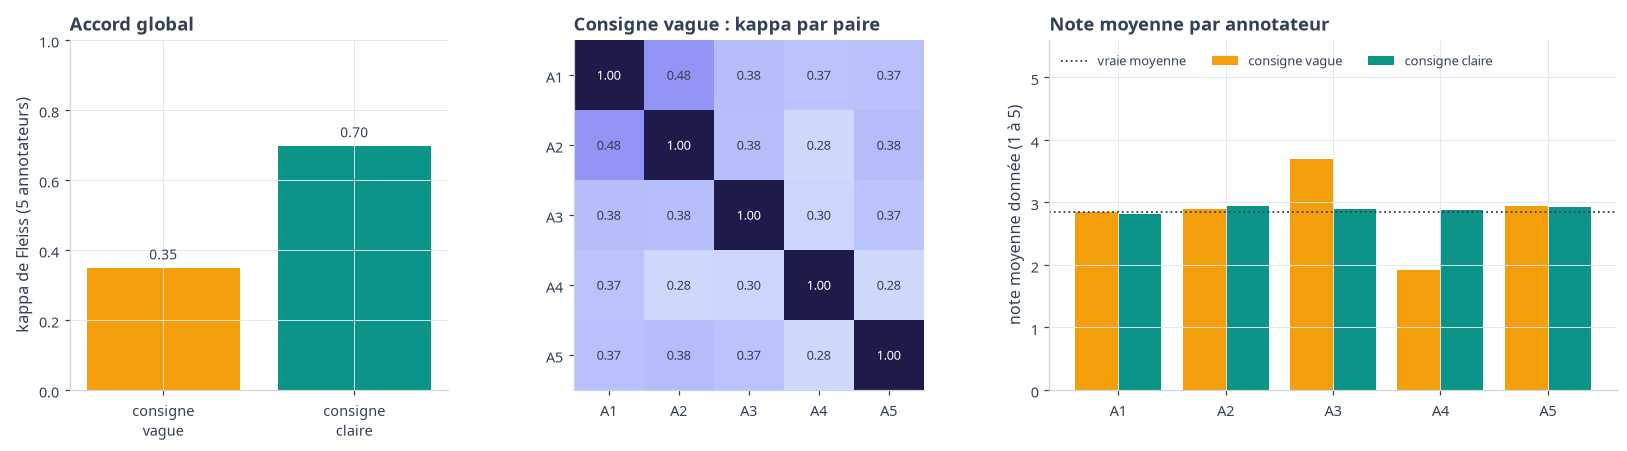

In [15]:
N_ITEMS, NOTES = 200, 5
vraies = rng.integers(0, NOTES, N_ITEMS)
vague = d8.simulate_annotators(vraies, [0.72, 0.7, 0.55, 0.55, 0.7], NOTES, seed=3, bias=[None, None, 4, 0, None])
claire = d8.simulate_annotators(vraies, [0.88, 0.9, 0.85, 0.9, 0.87], NOTES, seed=4)


def kappas_par_paire(R):
    m = R.shape[1]
    Kp = np.eye(m)
    for i in range(m):
        for j in range(i + 1, m):
            Kp[i, j] = Kp[j, i] = d8.cohen_kappa(R[:, i], R[:, j], labels=np.arange(NOTES))
    return Kp


fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [0.8, 1.1, 1.2]})
ax = axes[0]
kf = [d8.fleiss_kappa(d8.ratings_to_counts(R, NOTES)) for R in (vague, claire)]
ax.bar(["consigne\nvague", "consigne\nclaire"], kf, color=[AMBER, TEAL])
annotate_bars(ax, "{:.2f}")
ax.set_ylim(0, 1)
ax.set_ylabel("kappa de Fleiss (5 annotateurs)")
ax.set_title("Accord global")
ax = axes[1]
Kp = kappas_par_paire(vague)
ax.imshow(Kp, cmap="aie_seq", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{Kp[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if Kp[i, j] > 0.6 else SLATE)
ax.set_xticks(range(5), [f"A{i + 1}" for i in range(5)])
ax.set_yticks(range(5), [f"A{i + 1}" for i in range(5)])
ax.grid(False)
ax.set_title("Consigne vague : kappa par paire")
ax = axes[2]
xs = np.arange(5)
ax.bar(xs - 0.2, vague.mean(0) + 1, 0.4, color=AMBER, label="consigne vague")
ax.bar(xs + 0.2, claire.mean(0) + 1, 0.4, color=TEAL, label="consigne claire")
ax.axhline(vraies.mean() + 1, color=SLATE, ls=":", lw=1.2, label="vraie moyenne")
ax.set_xticks(xs, [f"A{i + 1}" for i in xs])
ax.set_ylim(0, 5.6)
ax.set_ylabel("note moyenne donnée (1 à 5)")
ax.set_title("Note moyenne par annotateur")
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
finish(fig)
plt.show()

La consigne claire fait nettement monter le kappa de Fleiss (voir la lecture de
Landis-Koch dans le tableau ci-dessous). Avec la consigne vague, la matrice des kappas
par paire est uniformément pâle : sur 200 items, elle ne suffit pas à désigner un
coupable. La **note moyenne par annotateur**, elle, le fait immédiatement : A3 note bien
au-dessus de la vraie moyenne (généreux), A4 bien en dessous (sévère). C'est exactement
l'inspection recommandée par le livre (section *Inspect Data*) : tracer les
distributions par annotateur, repérer ceux qui notent systématiquement plus haut ou plus
bas, puis décider quoi faire de leurs annotations (les recalibrer, les réannoter, les
écarter). L'exercice 8.3 approfondit ce diagnostic. Le kappa pondéré quadratique, adapté aux notes, est calculé ci-dessous pour
comparaison.

In [16]:
pd.DataFrame({
    "consigne": ["vague", "claire"],
    "Fleiss (non pondéré)": kf,
    "Cohen A1-A2": [d8.cohen_kappa(R[:, 0], R[:, 1]) for R in (vague, claire)],
    "Cohen pondéré quadratique A1-A2": [d8.cohen_kappa(R[:, 0], R[:, 1], "quadratic") for R in (vague, claire)],
    "lecture (Landis-Koch)": [d8.kappa_interpretation(k) for k in kf],
}).round(3)

,consigne,Fleiss (non pondéré),Cohen A1-A2,Cohen pondéré quadratique A1-A2,lecture (Landis-Koch)
0,vague,0.348,0.480,0.475,passable
1,claire,0.697,0.649,0.641,substantiel


> **À retenir.** La meilleure source de données est l'usage de sa propre application (le
> volant d'inertie). Les consignes d'annotation sont la partie la plus difficile et la
> plus rentable : elles servent aussi à l'évaluation. On mesure leur clarté par l'accord
> inter-annotateurs corrigé du hasard (kappa de Cohen pour deux annotateurs, de Fleiss
> pour plusieurs), jamais par l'accord brut.

## Synthèse

- **Vision centrée données** : à modèle de base partagé, les données font la différence ;
  la curation est un processus itératif, pas linéaire.
- **Formats** : séquences (auto-supervisé), (instruction, réponse) pour le SFT,
  triplets de préférence, exemples notés. Les comportements complexes (CoT, outils,
  multi-tours) sont chers à annoter.
- **Qualité** : six critères (pertinente, alignée, cohérente, bien formatée, unique,
  conforme). Le bruit aléatoire coûte des données, le bruit systématique coûte de la
  qualité.
- **Couverture** : à budget égal, couvrir toutes les façons de demander l'emporte ; on
  mesure la diversité en surface (distinct-$n$) et en sens (score de Vendi).
- **Quantité** : la courbe d'apprentissage suit souvent $a n^{-b} + c$ ; on extrapole
  depuis 25, 50, 100 % des données pour arbitrer le budget.
- **Annotation** : consignes précises, accord mesuré par les kappas de Cohen et de Fleiss.

**Liens avec les autres chapitres.** Les consignes d'annotation sont celles de
l'évaluation (chapitre 4) ; les données servent à l'affinage (chapitre 7, LoRA et PEFT
demandent moins d'exemples) ; le volant d'inertie s'appuie sur les retours utilisateurs
(chapitre 10). Le **cours 2** montre comment augmenter et synthétiser des données quand
l'annotation ne suffit pas, le **cours 3** comment les traiter.